# Recreating the UNR grid with GPS Imaging

The Nevada Geodetic Laboratory publishes gridded GPS for OPERA DISP calibration in two
products: a **time-constant** grid of MIDAS rates, and a **time-variable** grid of daily
positions. This notebook rebuilds both over Southern California from station positions,
with `geepers.gridding` and `geepers.gps_imaging`, and scores them against Version 0.3.

It follows the OPERA DISP-CAL ATBD, section 2.5, except where the published files show
otherwise. Those places are marked **inferred**, and collected at the end: they come from
reading the product, not from its authors.

To run another region, use the script, which does all of this for a box:

```bash
python scripts/recreate-unr-grid.py --bbox -118.5 33.8 -116.5 35.2 -o socal --workers 32
```

Running this notebook downloads about 800 station and grid files, roughly 0.5 GB. Set
`GEEPERS_UNR_CACHE` to keep them.

In [ ]:
%matplotlib inline
import multiprocessing as mp
import os
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from geepers import gridding
from geepers.gps_imaging import (
    great_circle_degrees,
    linked_stations,
    make_ssf,
    tri_vertex_neighbors,
)
from geepers.gps_sources import UnrGridSource, UnrSource
from scipy.spatial import Delaunay

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e4e3df",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"

CACHE = Path(os.environ.get("GEEPERS_UNR_CACHE", "unr_cache"))
WORKERS = min(32, os.cpu_count() or 1)
COMPONENTS = ("east", "north", "up")
BOX = (-118.5, 33.8, -116.5, 35.2)  # west, south, east, north
BUFFER = 1.5  # stations this far outside still feed the edge nodes
START, END = pd.Timestamp("2012-01-01"), pd.Timestamp("2026-03-06")
DAYS = pd.date_range(START, END - pd.Timedelta(days=1), freq="D")

stations_source = UnrSource(cache_dir=CACHE / "stations")
constant_source = UnrGridSource(gridded_type="constant", cache_dir=CACHE / "grid_constant")
variable_source = UnrGridSource(gridded_type="variable", cache_dir=CACHE / "grid_variable")

## 1. Nodes and stations

The grid is about 25 km apart. Stations beyond the box are kept, because a node's
neighbours can lie outside it.

52 nodes, 724 stations, 4059 catalogued steps


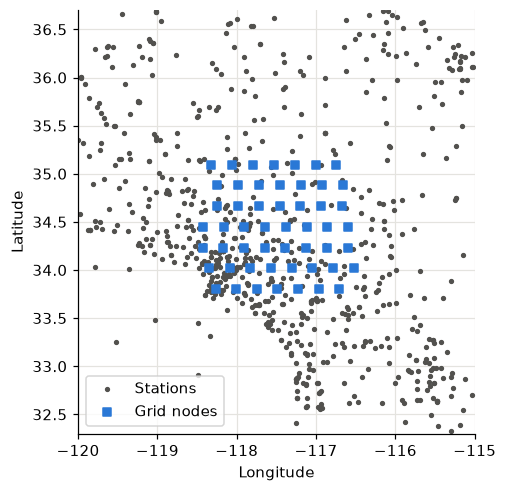

In [ ]:
nodes = pd.DataFrame(variable_source.stations(bbox=BOX))[["id", "lon", "lat"]].reset_index(drop=True)
west, south, east, north = BOX
outer = (west - BUFFER, south - BUFFER, east + BUFFER, north + BUFFER)
sites = pd.DataFrame(stations_source.stations(bbox=outer))[["id", "lon", "lat"]]
sites = sites.drop_duplicates("id").reset_index(drop=True)
steps = stations_source.steps(list(sites.id))
print(f"{len(nodes)} nodes, {len(sites)} stations, {len(steps)} catalogued steps")

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(sites.lon, sites.lat, s=6, color=MUTED, label="Stations")
ax.scatter(nodes.lon, nodes.lat, s=26, marker="s", color=BLUE, label="Grid nodes")
ax.set(xlim=outer[0::2], ylim=outer[1::2], aspect=1 / np.cos(np.radians(34.5)),
       xlabel="Longitude", ylabel="Latitude")
ax.legend(loc="lower left");

## 2. Station parameters

For each station: its MIDAS rate and uncertainty, its misfit to a trajectory model, a
variability index, and how long and complete its record is since 2012. The catalogued
steps keep MIDAS pairs from spanning them.

In [ ]:
def read_positions(site):
    try:
        df = stations_source.timeseries(site, frame="ENU", zero_by="none")
    except Exception:  # the station list includes sites with no series
        return None
    df = df.set_index(pd.DatetimeIndex(df["date"]).floor("D"))
    columns = [*COMPONENTS, *(f"sigma_{c}" for c in COMPONENTS)]
    df = df[columns] * 1000.0
    df = df[~df.index.duplicated()]
    return df[df.index < END]


step_dates = {s: pd.DatetimeIndex(g.date.unique()) for s, g in steps.groupby("id")}


def station_row(job):
    site, lon, lat = job
    df = read_positions(site)
    if df is None:
        return None
    row = gridding.station_parameters(df, step_dates.get(site, []), START)
    return None if row is None else {"id": site, "lon": lon, "lat": lat, **row}


jobs = [(s.id, s.lon, s.lat) for s in sites.itertuples()]
with ProcessPoolExecutor(WORKERS, mp_context=mp.get_context("fork")) as pool:
    rows = list(pool.map(station_row, jobs))
stats = pd.DataFrame([r for r in rows if r is not None])
print(f"{len(stats)} stations with at least 4 years")
stats[["id", "duration_since_start", "completeness", "ve", "se", "vu", "su", "misfit_u", "variability_u"]].head().round(2)

632 stations with at least 4 years


,id,duration_since_start,completeness,ve,se,vu,su,misfit_u,variability_u
0,7ODM,14.17,91.56,-27.40,0.18,0.09,0.53,4.58,1.94
1,ACSB,12.25,99.37,-38.85,0.14,-1.38,0.43,3.77,2.35
2,ACSX,9.87,99.25,-38.87,0.16,-1.30,0.50,3.71,2.40
3,AERO,10.89,38.55,-39.96,0.25,-1.09,0.79,3.44,2.13
4,AGMT,14.17,99.58,-18.72,0.12,0.24,0.32,3.95,2.09


## 3. GPS Imaging: one node

Imaging ([Hammond, Blewitt and Kreemer, 2016](https://doi.org/10.1002/2016JB013458)) is a robust
interpolator. A point is added to the Delaunay triangulation of the stations, the stations
connected to it are its neighbours, and its value is their **weighted median**, so a single
bad station cannot pull it.

Weights come from a spatial structure function (SSF) of distance. The ATBD's Figure 2-23
lists one node's stations with their weights, and `gridding.atbd_ssf` is that curve. It is
much flatter than one estimated regionally with `make_ssf`, and it matches the product much
better.

station    km  weight
   VNPS  7.19    0.18
   P517  8.08    0.18
   CJVG  9.32    0.18
   P587 17.87    0.16
   QHTP 21.30    0.16
   CMP9 24.89    0.15


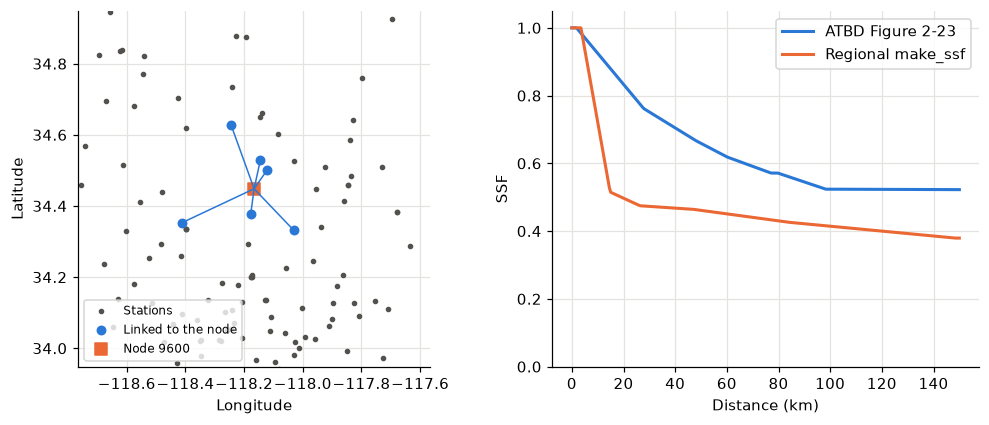

In [ ]:
ssf = gridding.atbd_ssf()
regional = make_ssf(stats.lon, stats.lat, stats.vu, stats.su)
km_per_degree = 111.195

node = nodes[nodes.id == 9600].iloc[0]
lon, lat = stats.lon.to_numpy(), stats.lat.to_numpy()
neighbors = tri_vertex_neighbors(Delaunay(np.c_[lon, lat]))
linked = linked_stations(lon, lat, node.lon, node.lat, neighbors)
km = great_circle_degrees(node.lat, node.lon, lat[linked], lon[linked]) * km_per_degree
weight = np.interp(km / km_per_degree, ssf[:, 0], ssf[:, 1])
print(pd.DataFrame({"station": stats.id.to_numpy()[linked], "km": km, "weight": weight / weight.sum()})
      .sort_values("km").round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.scatter(lon, lat, s=7, color=MUTED, label="Stations")
for j in linked:
    ax.plot([node.lon, lon[j]], [node.lat, lat[j]], color=BLUE, lw=1)
ax.scatter(lon[linked], lat[linked], s=30, color=BLUE, label="Linked to the node")
ax.scatter(node.lon, node.lat, s=70, marker="s", color=ORANGE, label="Node 9600")
ax.set(xlim=(node.lon - 0.6, node.lon + 0.6), ylim=(node.lat - 0.5, node.lat + 0.5),
       aspect=1 / np.cos(np.radians(node.lat)), xlabel="Longitude", ylabel="Latitude")
ax.legend(loc="lower left", fontsize=8)
ax = axes[1]
d = np.linspace(0, 150, 300)
ax.plot(d, np.interp(d / km_per_degree, ssf[:, 0], ssf[:, 1]), color=BLUE, lw=2, label="ATBD Figure 2-23")
ax.plot(d, np.interp(d / km_per_degree, regional[:, 0], regional[:, 1]), color=ORANGE, lw=2, label="Regional make_ssf")
ax.set(xlabel="Distance (km)", ylabel="SSF", ylim=(0, 1.05))
ax.legend();

## 4. Filtering the rates

Each station's rate is replaced by the weighted median of its Delaunay neighbours, 30 times
with the SSF perturbed by up to 20%, and the median of those is kept. This removes outliers
and speckle. The difference from the original rate is also what the selection step calls
speckle.

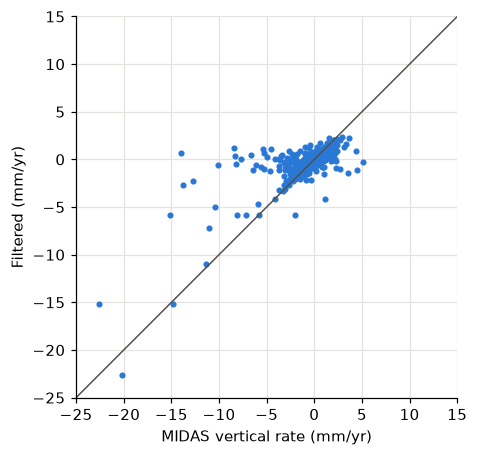

In [ ]:
stats = stats.join(gridding.filter_station_rates(stats, ssf))
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(stats.vu, stats.vmsfu, s=9, color=BLUE)
limits = np.array([-25, 15])
ax.plot(limits, limits, color=MUTED, lw=1)
ax.set(xlim=limits, ylim=limits, aspect=1, xlabel="MIDAS vertical rate (mm/yr)", ylabel="Filtered (mm/yr)");

## 5. The time-constant grid

Stations are declustered, keeping the smallest vertical uncertainty within 10 m, and the
filtered rates are imaged onto the nodes. Here weights are SSF / velocity sigma, as Eq. (6)
says. The published files are exact straight lines, so their slopes are the published rates.

,component,rms_mm_yr,r
0,east,0.235,0.999
1,north,0.360,0.998
2,up,0.135,0.968


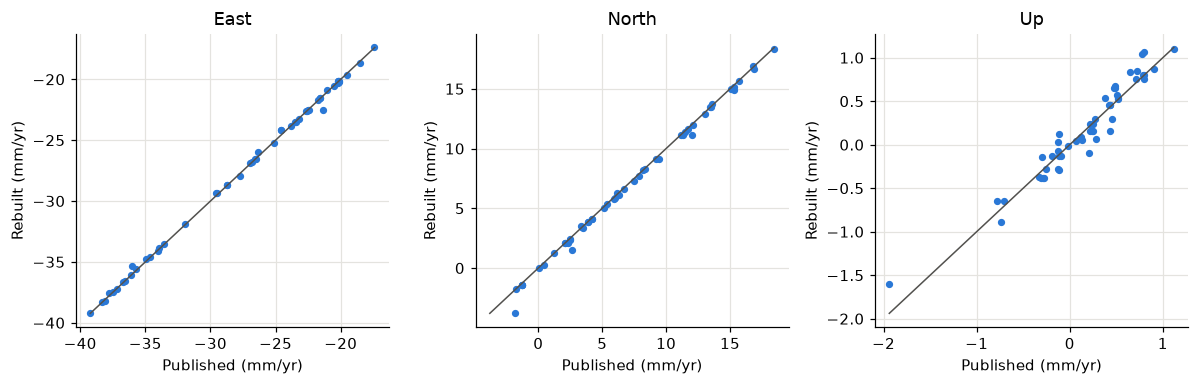

In [ ]:
rates = gridding.rate_grid(gridding.decluster(stats), nodes.lon, nodes.lat, ssf)
published_rates = pd.DataFrame(
    [
        {f"v{c[0]}": np.polyfit(df.decimal_year, df[c], 1)[0] for c in COMPONENTS}
        for df in map(constant_source.node_series, nodes.id)
    ]
)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
rows = []
for ax, c in zip(axes, COMPONENTS):
    key = f"v{c[0]}"
    ours, theirs = rates[key].to_numpy(), published_rates[key].to_numpy()
    span = np.array([min(ours.min(), theirs.min()), max(ours.max(), theirs.max())])
    ax.plot(span, span, color=MUTED, lw=1)
    ax.scatter(theirs, ours, s=14, color=BLUE)
    ax.set(xlabel="Published (mm/yr)", ylabel="Rebuilt (mm/yr)", title=c.capitalize())
    rows.append({"component": c, "rms_mm_yr": np.sqrt(np.mean((ours - theirs) ** 2)), "r": np.corrcoef(ours, theirs)[0, 1]})
fig.tight_layout()
pd.DataFrame(rows).round(3)

## 6. Selecting stations for the daily grid

The ATBD asks for at least 7 years since 2012, 80% completeness, and limits on speckle,
misfit and variability. **Inferred:** the completeness limit does not match the product, as
published nodes follow stations it rejects. So it is dropped here.

In [ ]:
atbd = stats[gridding.select_time_variable(stats)]
relaxed = gridding.SelectionCriteria(min_completeness=0.0)
chosen = gridding.decluster(stats[gridding.select_time_variable(stats, relaxed)])
print(f"{len(stats)} stations, {len(atbd)} pass the ATBD rules, {len(chosen)} used here")

632 stations, 427 pass the ATBD rules, 489 used here


## 7. Filling the gaps

Every station needs a position every day. Equipment steps are removed from 30 days of data
either side. Earthquake steps are signal, and stay. Outliers become gaps. Each gap then
takes the weighted-median displacement of the stations around it since the nearest day with
data on either side, unless an earthquake intervenes. A second pass treats filled days as
data, and a trajectory model fills what is left.

{'observed': 2124086, 'spatial_pass_1': 401495, 'spatial_pass_2': 4576, 'model': 1885}


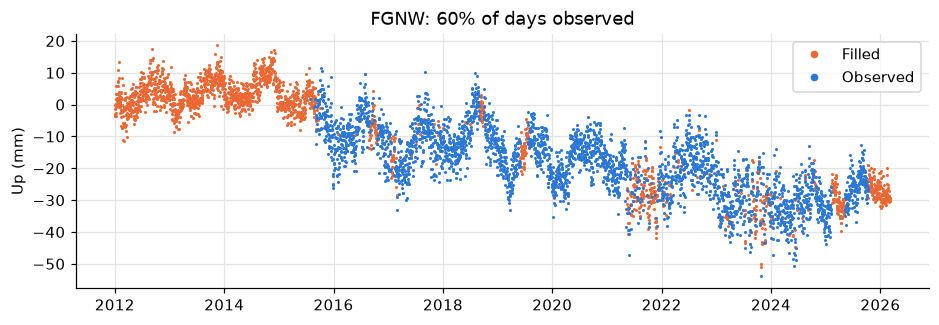

In [ ]:
equipment = {s: pd.DatetimeIndex(g.date.unique()) for s, g in steps[steps.code == 1].groupby("id")}
quakes = {s: pd.DatetimeIndex(g.date.unique()) for s, g in steps[steps.code == 2].groupby("id")}
series = {s: read_positions(s) for s in chosen.id}
cube = gridding.build_position_cube(series, chosen, DAYS, equipment, quakes)
print(gridding.fill_gaps(cube, ssf, n_workers=WORKERS))

share = cube.observed.mean(axis=1)
pick = int(np.argmin(np.abs(share - 0.6)))
fig, ax = plt.subplots(figsize=(10, 3))
y = cube.x[pick, :, 2] - cube.x[pick, 0, 2]
ax.plot(DAYS[~cube.observed[pick]], y[~cube.observed[pick]], ".", ms=2, color=ORANGE, label="Filled")
ax.plot(DAYS[cube.observed[pick]], y[cube.observed[pick]], ".", ms=2, color=BLUE, label="Observed")
ax.set(ylabel="Up (mm)", title=f"{cube.sites[pick]}: {share[pick]:.0%} of days observed")
ax.legend(markerscale=4);

## 8. Imaging each day

Displacement since the first day is imaged onto the nodes.

**Inferred:** the daily weights use distance alone, with no sigma. Replaying the published
medians with UNR's own station values, that picks the station UNR used far more often than
any rule with a daily, median or velocity sigma, or with temporal or spatial variability. In
the ATBD's own example IDML has extreme uncertainty and variability, yet its weight sits on
the distance curve. It is the default here, and `weight_by_sigma=True` gives Eq. (6) as written.

In [ ]:
images = gridding.image_positions(cube, nodes.lon, nodes.lat, ssf, n_workers=WORKERS)
with_sigma = gridding.image_positions(cube, nodes.lon, nodes.lat, ssf, n_workers=WORKERS, weight_by_sigma=True)
published = {int(n): variable_source.node_series(int(n)).reindex(DAYS) for n in nodes.id}


def monthly_rms(grid):
    rows = []
    for j, n in enumerate(nodes.id):
        for k, c in enumerate(COMPONENTS):
            error = grid[:, j, k] - published[int(n)][c].to_numpy()
            error = pd.Series(error - np.nanmedian(error), index=DAYS).resample("30D").median()
            rows.append({"id": int(n), "component": c, "rms": np.sqrt(np.nanmean(error**2)),
                         "sigma": published[int(n)][f"sigma_{c}"].median()})
    return pd.DataFrame(rows)


ours, sigma_rule = monthly_rms(images), monthly_rms(with_sigma)
pd.DataFrame(
    {
        "distance only (mm)": ours.groupby("component").rms.median(),
        "with daily sigma (mm)": sigma_rule.groupby("component").rms.median(),
        "published sigma (mm)": ours.groupby("component").sigma.median(),
    }
).loc[list(COMPONENTS)].round(2)

,distance only (mm),with daily sigma (mm),published sigma (mm)
component,,,
east,0.89,2.87,1.07
north,1.25,2.16,1.24
up,1.58,1.76,4.58


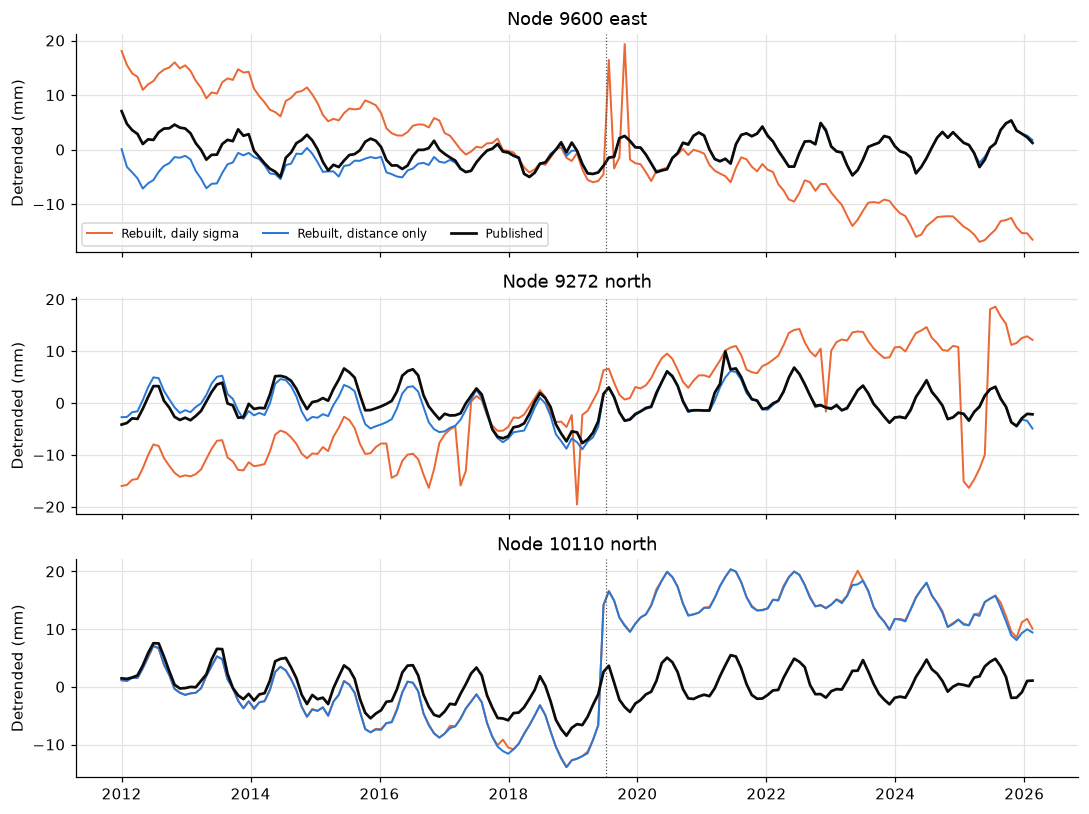

In [ ]:
monthly = lambda v: pd.Series(v, index=DAYS).resample("30D").median()
cases = ((9600, "east"), (9272, "north"), (10110, "north"))
ids = nodes.id.tolist()
fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
for ax, (n, c) in zip(axes, cases):
    theirs = published[n][c].to_numpy()
    good = np.isfinite(theirs)
    t = np.arange(len(DAYS))
    trend = np.polyval(np.polyfit(t[good], theirs[good], 1), t)
    k = COMPONENTS.index(c)
    for grid, color, label in ((with_sigma, ORANGE, "Rebuilt, daily sigma"), (images, BLUE, "Rebuilt, distance only")):
        y = grid[:, ids.index(n), k]
        ax.plot(monthly(y - np.nanmedian(y - theirs) - trend), color=color, lw=1.3, label=label)
    ax.plot(monthly(theirs - trend), color=INK, lw=1.8, label="Published")
    ax.axvline(pd.Timestamp("2019-07-05"), color=MUTED, lw=0.8, ls=":")
    ax.set(ylabel="Detrended (mm)", title=f"Node {n} {c}")
axes[0].legend(ncol=3, fontsize=8)
fig.tight_layout()

Most nodes now follow the published series. Node 10110 does not: the rebuild picks up a
large step at Ridgecrest in 2019 (dotted) that the product does not have. That is one of the
open problems below.

## 9. How to see which station a node follows

A weighted median returns one station's value. So on days a node follows a station, node
minus station is a constant, to the rounding of the file. That is what makes the inferences
here possible: it needs no assumption about the recipe.

VNPS: the most common value of node minus station covers 4002 of 4897 days
P517: the most common value of node minus station covers 721 of 5144 days


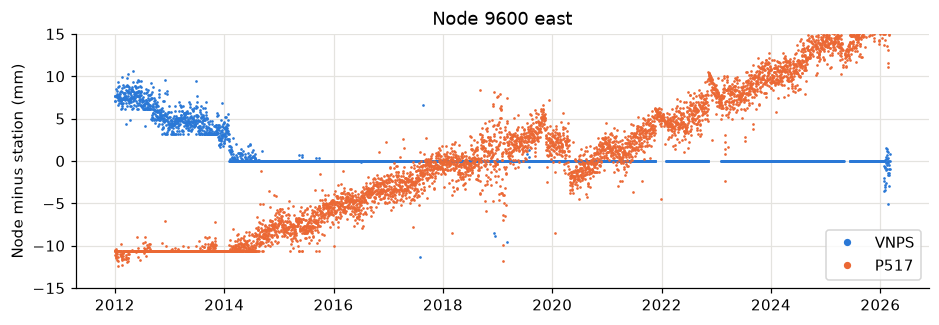

In [ ]:
theirs = published[9600]["east"]
fig, ax = plt.subplots(figsize=(10, 3))
for site, color in (("VNPS", BLUE), ("P517", ORANGE)):
    df = read_positions(site)
    df = df[df.index >= START]
    difference = (theirs.reindex(df.index) - df["east"]).round(2)
    difference = difference - difference.median()
    ax.plot(difference, ".", ms=1.5, color=color, label=site)
    value = difference.round(2).value_counts()
    print(f"{site}: the most common value of node minus station covers {value.iloc[0]} of {len(df)} days")
ax.set(ylabel="Node minus station (mm)", ylim=(-15, 15), title="Node 9600 east")
ax.legend(markerscale=5);

## What is documented, and what is inferred

| Step | Source |
|---|---|
| MIDAS rates, filter, declustering, rate imaging with SSF / sigma | ATBD |
| Spatial gap filling, earthquake rule, model fallback | ATBD |
| SSF | Read from the weights of ATBD Figure 2-23 |
| Daily weights by distance alone | **Inferred** from the published files |
| No 80% completeness limit on daily stations | **Inferred** from the published files |

## What is not reproduced

- **Equipment step corrections.** UNR's can be recovered from the files, and no estimator
  tried here matches them, including the iteration in the ATBD. This is the largest remaining
  difference: with UNR's corrections fed back in, the Southern California error falls to
  about 0.6 / 0.9 / 1.0 mm.
- **The exact station list.** Rules recover it only roughly.
- **A few nodes**, such as 10110 at Ridgecrest, probably through a filled station.
- **Unmatched days in sparse networks.** In northern Nevada more than half of node days do
  not equal one station plus a constant.
- **Sparse networks.** Alaska, Hawaii and the Aleutians agree less well than this region, even
  with a wider `--buffer`. Boxes do not wrap the dateline.

## Options not used above

Links across faults or plate boundaries can be removed with `breaklines`, a list of (lon, lat)
polylines, in the filter, the filling and the imaging. A background model can be added to the
rate grid with `background` and `background_weight`. Over Southern California, San Andreas
and plate-boundary breaklines moved the result away from the product and raised leave-one-out
error near the fault, while a Gulf of California breakline helped on the mainland side.